# Local-volatility benchmark
## SSVI total implied variance -> Dupire local volatility -> PDE price and delta

This notebook implements a deliberately small but complete local-volatility benchmark for the SPX option data used by the Black-Scholes implied-volatility-function notebooks.

The model pipeline is

$$
\text{option quotes}
\longrightarrow
w_{\mathrm{mkt}}(k,T)
\longrightarrow
\text{SSVI fit}
\longrightarrow
\sigma_{\mathrm{loc}}(k,T)
\longrightarrow
\text{backward local-volatility valuation PDE}.
$$

The main outputs are:

- same-day PDE prices and PDE deltas;
- frozen-parameter next-day prices;
- one-day delta-hedging errors;
- SSVI and Dupire validity diagnostics.

### Precise next-day protocol

For comparability with the Black-Scholes implied-volatility-function benchmark, the day-$t$ SSVI parameterization is frozen, but it is evaluated on day $t+1$ using:

- the realised day-$t+1$ spot;
- the day-$t+1$ forward and zero rate;
- the remaining time to expiry.

No day-$t+1$ option price or implied volatility is used in the model price. This is a **frozen-parameter next-day forecast**. It is not the stricter alternative of conditioning the entire day-$t$ local-volatility process and day-$t$ yield curves on the realised day-$t+1$ spot.

### Sources used for the implementation

1. Jim Gatheral, *The Volatility Surface*, Chapters 1 and 3: Dupire local variance and SVI.
2. Jim Gatheral and Antoine Jacquier, *Arbitrage-free SVI volatility surfaces*: SSVI and sufficient static-arbitrage conditions.
3. Jack Jacquier's `SSVILocalVol.ipynb`: the Heston-like SSVI backbone and analytic $k$-derivatives.
4. IceCurrent's `local_volatility_model`: the overall data-to-surface-to-PDE pipeline, the log-spot Crank-Nicolson structure, and the constant-volatility validation pattern.

Repository references:

- https://github.com/JackJacquier/SSVI
- https://github.com/IceCurrent/local_volatility_model

The code below is written directly in this notebook. QuantLib, TensorFlow and Andreasen-Huge are not used.

# Shared IvyDB preparation for the SPX benchmarks

Sections 1-10 deliberately preserve the same market-data structure used by the Black-Scholes implied-volatility-function notebook.

The common market universe is `quotes_all`. It retains both ITM and OTM options.

The calibration universe is `calibration_quotes`. Its default is OTM-only. This avoids fitting both sides of an almost repeated put-call-parity pair, while the wider universe remains available for pricing and hedging evaluation.

For later comparisons, the stable identifier is

```text
pair_id = date | date_next | optionid
```

Models should be compared only on the intersection of their available `pair_id` values.

## 1. Imports, filenames and modelling choices

All material numerical choices are collected here.

The settings determining the common quote universe should remain unchanged across the Black-Scholes, local-volatility, Heston and neural-SDE notebooks.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from tqdm import tqdm

from scipy.interpolate import PchipInterpolator
from scipy.linalg import solve_banded
from scipy.optimize import brentq, least_squares
from scipy.stats import norm

pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 170)

DATA_FOLDER = Path(".")

OPTIONS_FILE = DATA_FOLDER / "one_month_spx_option_price.csv"
SPOT_FILE = DATA_FOLDER / "one_month_spx_security_price.csv"
FORWARD_FILE = DATA_FOLDER / "one_month_spx_forward_price.csv"
RATE_FILE = DATA_FOLDER / "one_month_spx_zero_coupon_yield_curve.csv"

TARGET_SECID = 108105

MIN_DTE = 14
MAX_DTE = 365
MAX_ABS_LOG_MONEYNESS = 0.30
MAX_RELATIVE_SPREAD = 0.50

CALIBRATE_ON_OTM_ONLY = True

# Primary calibration weight:
# inverse squared total bid-ask implied variance width.
WEIGHT_MODE = "bid_ask_total_variance"

# The raw weights are normalised within each date and capped.
# The min ensures wide bid-ask spread quotes remain numerically relevant (5% median)
# The cap prevents a single extremely tight quote from dominating the fit.
MIN_NORMALISED_WEIGHT = 0.05
MAX_NORMALISED_WEIGHT = 20.0
TOTAL_VARIANCE_WIDTH_FLOOR = 1e-6

MIN_QUOTES_PER_EXPIRY = 5
MIN_EXPIRIES_PER_DATE = 3
MAX_FIT_EVALUATIONS = 2500

# Dupire diagnostics and PDE safeguards.
DIAGNOSTIC_K_MAX = 0.60
LOCAL_VOLATILITY_MIN = 0.01
LOCAL_VOLATILITY_MAX = 3.00

# One log-spot grid is used for every option in one date-expiry group.
PDE_SPACE_POINTS = 301
PDE_TIME_STEPS_PER_YEAR = 400
PDE_LOG_SPOT_WIDTH = 1.00
RANNACHER_FULL_STEPS = 2

RUN_VEGA_WEIGHT_SENSITIVITY = False

CACHE_FOLDER = Path("local_vol_cache")
CACHE_FOLDER.mkdir(exist_ok=True)

print("Imports and settings completed.")

Imports and settings completed.


## 2. Load the four raw CSV files

Each table has one role:

- `options_raw`: SPX option quotes;
- `spot_raw`: the daily SPX index level;
- `forwards_raw`: the forward index level for each expiry and settlement convention;
- `rates_raw`: the zero-coupon curve for each quote date.

In [2]:
options_raw = pd.read_csv(OPTIONS_FILE, low_memory=False)
spot_raw = pd.read_csv(SPOT_FILE)
forwards_raw = pd.read_csv(FORWARD_FILE)
rates_raw = pd.read_csv(RATE_FILE)

print("Raw shapes")
print("options: ", options_raw.shape)
print("spot:    ", spot_raw.shape)
print("forwards:", forwards_raw.shape)
print("rates:   ", rates_raw.shape)

Raw shapes
options:  (326964, 27)
spot:     (20, 7)
forwards: (1192, 7)
rates:    (220, 3)


## 3. Basic option cleaning

This block performs only the cleaning required for a common benchmark:

1. parse dates and numeric columns;
2. divide IvyDB `strike_price` by 1,000;
3. construct midpoint and spread;
4. retain standard European SPX contracts;
5. remove invalid or very wide quotes;
6. retain 14-365 days to expiry.

The SPX contract multiplier is 100. The factor 1,000 applies only to IvyDB's stored strike.

In [3]:
options = options_raw.copy()

if "forward_price" in options.columns:
    options = options.drop(columns=["forward_price"])

options["date"] = pd.to_datetime(options["date"], errors="coerce")
options["exdate"] = pd.to_datetime(options["exdate"], errors="coerce")

numeric_columns = [
    "secid",
    "strike_price",
    "best_bid",
    "best_offer",
    "impl_volatility",
    "delta",
    "vega",
    "optionid",
    "am_settlement",
    "contract_size",
]

for column in numeric_columns:
    if column in options.columns:
        options[column] = pd.to_numeric(options[column], errors="coerce")

options["strike"] = options["strike_price"] / 1000.0
options["mid"] = (options["best_bid"] + options["best_offer"]) / 2.0
options["spread"] = options["best_offer"] - options["best_bid"]
options["relative_spread"] = options["spread"] / options["mid"]
options["dte"] = (options["exdate"] - options["date"]).dt.days
options["T"] = options["dte"] / 365.0

standard_contract = (
    options["ss_flag"].astype(str).isin(["0", "0.0"])
    & options["contract_size"].eq(100)
)

# minimal validity requirements
valid_quote = (
    options["best_bid"].gt(0)
    & options["best_offer"].ge(options["best_bid"])
    & options["mid"].gt(0)
    & options["relative_spread"].le(MAX_RELATIVE_SPREAD)
)

# cleaning condition incorporating standard_contract and valid_quote
basic_keep = (
    options["secid"].eq(TARGET_SECID)
    & options["exercise_style"].astype(str).str.upper().eq("E")
    & options["cp_flag"].isin(["C", "P"])
    & standard_contract
    & valid_quote
    & options["strike"].gt(0)
    & options["dte"].between(MIN_DTE, MAX_DTE)
)

rows_before = len(options)
options = options.loc[basic_keep].copy()

duplicate_count = options.duplicated(["optionid", "date"]).sum()
if duplicate_count > 0:
    raise ValueError(
        f"Found {duplicate_count} duplicate (optionid, date) observations."
    )

print(f"Rows before basic cleaning: {rows_before:,}")
print(f"Rows after basic cleaning:  {len(options):,}")

Rows before basic cleaning: 326,964
Rows after basic cleaning:  316,297


## 4. Clean and merge spot and forward prices

The merge keys are:

- spot: `(secid, date)`;
- forward: `(secid, date, exdate, am_settlement)`.

The settlement flag is essential because AM- and PM-settled SPX contracts can share the same calendar expiry.

In [4]:
spot = spot_raw.copy()
spot["date"] = pd.to_datetime(spot["date"], errors="coerce")
spot["secid"] = pd.to_numeric(spot["secid"], errors="coerce")
spot["close"] = pd.to_numeric(spot["close"], errors="coerce")

spot = (
    spot.loc[spot["secid"].eq(TARGET_SECID), ["secid", "date", "close"]]
    .rename(columns={"close": "spot"})
    .copy()
)

if spot.duplicated(["secid", "date"]).any():
    raise ValueError("Security Prices is not unique on (secid, date).")

forwards = forwards_raw.rename(
    columns={
        "expiration": "exdate",
        "AMSettlement": "am_settlement",
        "ForwardPrice": "forward_price",
    }
).copy()

forwards["date"] = pd.to_datetime(forwards["date"], errors="coerce")
forwards["exdate"] = pd.to_datetime(forwards["exdate"], errors="coerce")
forwards["secid"] = pd.to_numeric(forwards["secid"], errors="coerce")
forwards["am_settlement"] = pd.to_numeric(
    forwards["am_settlement"], errors="coerce"
)
forwards["forward_price"] = pd.to_numeric(
    forwards["forward_price"], errors="coerce"
)

forwards = forwards.loc[
    forwards["secid"].eq(TARGET_SECID),
    ["secid", "date", "exdate", "am_settlement", "forward_price"],
].copy()

forward_key = ["secid", "date", "exdate", "am_settlement"]

if forwards.duplicated(forward_key).any():
    raise ValueError(
        "Forward Prices is not unique after including AM settlement."
    )


options = options.merge(
    spot,
    on=["secid", "date"],
    how="left",
    validate="many_to_one",
)

options = options.merge(
    forwards,
    on=forward_key,
    how="left",
    validate="many_to_one",
)

print("Missing spot values:   ", options["spot"].isna().sum())
print("Missing forward values:", options["forward_price"].isna().sum())

Missing spot values:    0
Missing forward values: 0


## 5. Interpolate the zero rate

IvyDB supplies zero rates at selected maturities. Linear interpolation (`interp`) gives the continuously compounded zero rate on each date. Then, the discount factor is

$$
D(t,T)=e^{-rT}.
$$

The maturity filter keeps options inside the downloaded curve range: this cell does not extrapolate.

In [5]:
rates = rates_raw.copy()
rates["date"] = pd.to_datetime(rates["date"], errors="coerce")
rates["days"] = pd.to_numeric(rates["days"], errors="coerce")
rates["rate"] = pd.to_numeric(rates["rate"], errors="coerce")
rates["rate_decimal"] = rates["rate"] / 100.0

options["rate"] = np.nan

for date in options["date"].dropna().unique():
    rows_today = options["date"].eq(date)

    # interest rates today
    curve_today = rates.loc[rates["date"].eq(date)].sort_values("days")

    if curve_today.empty:
        continue

    dte_today = options.loc[rows_today, "dte"]

    # this is the condition to be imposed on all dte's of today
    inside_curve = (
        dte_today.ge(curve_today["days"].min())
        & dte_today.le(curve_today["days"].max())
    )

    valid_indices = dte_today.index[inside_curve]

    # interpolating the rate: updating the rate col at the rows indicated by valid indices
    options.loc[valid_indices, "rate"] = np.interp(
        options.loc[valid_indices, "dte"],  # what should rate be at dte
        curve_today["days"],  # known dte value
        curve_today["rate_decimal"],  # known rate value
    )

options["discount"] = np.exp(-options["rate"] * options["T"])

print("Missing interpolated rates:", options["rate"].isna().sum())

Missing interpolated rates: 0


## 6. Final common quote universe

Forward log-moneyness is

$$
k=\log\left(\frac{K}{F}\right).
$$

At this stage we:

- require matched spot, forward and zero rate;
- retain a moderate forward log-moneyness range;
- remove midpoint prices outside elementary European no-arbitrage bounds;
- label OTM options without deleting ITM options.

The result, `quotes_all`, is the shared cleaned universe.

In [6]:
# drop rows where any value of categories in the subset is missing
options = options.dropna(
    subset=[
        "date",
        "exdate",
        "optionid",
        "spot",
        "forward_price",
        "rate",
        "discount",
    ]
).copy()

options["moneyness"] = options["strike"] / options["forward_price"] - 1.0
options["log_moneyness"] = np.log(
    options["strike"] / options["forward_price"]
)

is_call = options["cp_flag"].eq("C")
is_put = options["cp_flag"].eq("P")

# otm rows
options["is_otm"] = (
    (is_call & options["strike"].ge(options["forward_price"]))
    | (is_put & options["strike"].lt(options["forward_price"]))
)

# code logic: if is_call, yield 1st argument, otherwise 2nd argument
options["lower_bound"] = np.where(
    is_call,
    options["discount"]
    * np.maximum(options["forward_price"] - options["strike"], 0.0),
    options["discount"]
    * np.maximum(options["strike"] - options["forward_price"], 0.0),
)

# same code logic here; this computes the upper bound for the option mid price
options["upper_bound"] = np.where(
    is_call,
    options["discount"] * options["forward_price"],
    options["discount"] * options["strike"],
)

# make sure the mid price is numerically distant enough from the bounds
inside_bounds = (
    options["mid"].gt(options["lower_bound"] + 1e-10)
    & options["mid"].lt(options["upper_bound"] - 1e-10)
)

# final condition package, adding in the log moneyness constraint
common_keep = (
    options["log_moneyness"].abs().le(MAX_ABS_LOG_MONEYNESS)
    & inside_bounds
)

quotes_all = options.loc[common_keep].copy()
quotes_all = quotes_all.sort_values(["date", "optionid"]).reset_index(drop=True)

if CALIBRATE_ON_OTM_ONLY:
    calibration_quotes = quotes_all.loc[quotes_all["is_otm"]].copy()
else:
    calibration_quotes = quotes_all.copy()

print(f"Common clean quotes: {len(quotes_all):,}")
print(f"Calibration quotes:  {len(calibration_quotes):,}")
print(f"OTM share of common quotes: {quotes_all['is_otm'].mean():.2%}")
print(f"Dates: {quotes_all['date'].nunique()}")
print(f"Contracts: {quotes_all['optionid'].nunique()}")

Common clean quotes: 243,997
Calibration quotes:  125,746
OTM share of common quotes: 51.54%
Dates: 20
Contracts: 18290


## 7. Common spread statistics

These statistics describe `quotes_all`, not a model-specific subset.

Average bid-ask spread: 3.4692
Median bid-ask spread:  0.8000
Average relative spread: 2.39%
0.500     0.8
0.750     6.6
0.900     8.6
0.950    10.8
0.995    21.1
Name: spread, dtype: float64
Min spread: 0.04999999999999982
Max spread: 72.0


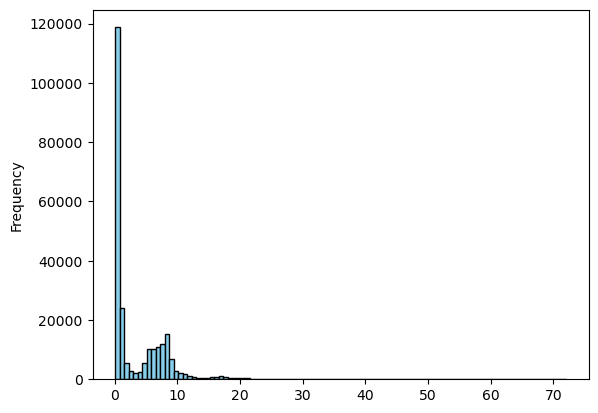

In [7]:
average_spread = quotes_all["spread"].mean()
median_spread = quotes_all["spread"].median()
average_relative_spread = quotes_all["relative_spread"].mean()

print(f"Average bid-ask spread: {average_spread:.4f}")
print(f"Median bid-ask spread:  {median_spread:.4f}")
print(f"Average relative spread: {average_relative_spread:.2%}")

# post-cleaning options

quotes_all["spread"].plot(kind="hist", bins=100, edgecolor="black", color="skyblue")
print(quotes_all["spread"].quantile([0.5, 0.75, 0.9, 0.95, 0.995]))

print("Min spread:", min(quotes_all["spread"]))
print("Max spread:", max(quotes_all["spread"]))

## 8. Black-Scholes utilities

The forward-form Black-Scholes price is

$$
C=D\left(FN(d_1)-KN(d_2)\right).
$$

The spot delta is

$$
\Delta_{\mathrm{call}}
=
D\frac{F}{S}N(d_1).
$$

Black-Scholes is used only to:

- convert market prices into implied volatility;
- construct total implied variance;
- construct calibration weights;
- validate the PDE when local volatility is constant.

In [8]:
def bs_price(cp_flag, forward, strike, T, discount, sigma):
    cp_flag = np.asarray(cp_flag)
    forward = np.asarray(forward, dtype=float)
    strike = np.asarray(strike, dtype=float)
    T = np.asarray(T, dtype=float)
    discount = np.asarray(discount, dtype=float)
    sigma = np.asarray(sigma, dtype=float)

    sqrt_T = np.sqrt(T)

    d1 = (
        np.log(forward / strike)
        + 0.5 * sigma**2 * T
    ) / (sigma * sqrt_T)

    d2 = d1 - sigma * sqrt_T

    call = discount * (
        forward * norm.cdf(d1)
        - strike * norm.cdf(d2)
    )

    put = discount * (
        strike * norm.cdf(-d2)
        - forward * norm.cdf(-d1)
    )

    return np.where(cp_flag == "C", call, put)


def bs_delta(cp_flag, spot, forward, strike, T, discount, sigma):
    cp_flag = np.asarray(cp_flag)
    spot = np.asarray(spot, dtype=float)
    forward = np.asarray(forward, dtype=float)
    strike = np.asarray(strike, dtype=float)
    T = np.asarray(T, dtype=float)
    discount = np.asarray(discount, dtype=float)
    sigma = np.asarray(sigma, dtype=float)

    sqrt_T = np.sqrt(T)

    d1 = (
        np.log(forward / strike)
        + 0.5 * sigma**2 * T
    ) / (sigma * sqrt_T)

    carry_discount = discount * forward / spot

    call_delta = carry_discount * norm.cdf(d1)
    put_delta = carry_discount * (norm.cdf(d1) - 1.0)

    return np.where(cp_flag == "C", call_delta, put_delta)


def bs_vega(forward, strike, T, discount, sigma):
    forward = np.asarray(forward, dtype=float)
    strike = np.asarray(strike, dtype=float)
    T = np.asarray(T, dtype=float)
    discount = np.asarray(discount, dtype=float)
    sigma = np.asarray(sigma, dtype=float)

    sqrt_T = np.sqrt(T)

    d1 = (
        np.log(forward / strike)
        + 0.5 * sigma**2 * T
    ) / (sigma * sqrt_T)

    return discount * forward * norm.pdf(d1) * sqrt_T


def implied_volatility_from_price(
    cp_flag,
    forward,
    strike,
    T,
    discount,
    market_price,
):
    def pricing_error(sigma):
        model_price = bs_price(
            cp_flag,
            forward,
            strike,
            T,
            discount,
            sigma,
        )
        return float(model_price - market_price)

    try:
        return brentq(pricing_error, 0.001, 5.0)
    except ValueError:
        return np.nan

## 9. Build common one-trading-day evaluation pairs

A quote on date $t$ is paired with the same `optionid` on the next SPX trading date.

Reappearance after a longer gap is not treated as a one-day observation.

In [9]:
trading_dates = sorted(spot["date"].dropna().unique())

next_date_map = {
    trading_dates[i]: trading_dates[i + 1]
    for i in range(len(trading_dates) - 1)
}

today = quotes_all.copy()
today["date_next"] = today["date"].map(next_date_map)

# if there's no tomorrow's quote, today's quote isn't kept as well since we're building pairs
today = today.dropna(subset=["date_next"]).copy()  

tomorrow_columns = [
    "optionid",
    "date",
    "exdate",
    "cp_flag",
    "strike",
    "mid",
    "best_bid",
    "best_offer",
    "spot",
    "forward_price",
    "rate",
    "discount",
    "T",
    "dte",
    "moneyness",
    "log_moneyness",
    "is_otm",
]

tomorrow = quotes_all[tomorrow_columns].copy()

tomorrow = tomorrow.rename(
    columns={
        "date": "date_next",
        "exdate": "exdate_next",
        "cp_flag": "cp_flag_next",
        "strike": "strike_next",
        "mid": "mid_next",
        "best_bid": "best_bid_next",
        "best_offer": "best_offer_next",
        "spot": "spot_next",
        "forward_price": "forward_price_next",
        "rate": "rate_next",
        "discount": "discount_next",
        "T": "T_next",
        "dte": "dte_next",
        "moneyness": "moneyness_next",
        "log_moneyness": "log_moneyness_next",
        "is_otm": "is_otm_next",
    }
)

evaluation_pairs = today.merge(
    tomorrow,
    on=["optionid", "date_next"],
    how="inner",
    validate="one_to_one",
)

evaluation_pairs["pair_id"] = (
    evaluation_pairs["date"].dt.strftime("%Y-%m-%d")
    + "|"
    + evaluation_pairs["date_next"].dt.strftime("%Y-%m-%d")
    + "|"
    + evaluation_pairs["optionid"].astype("Int64").astype(str)
)

evaluation_pairs["option_change"] = (
    evaluation_pairs["mid_next"] - evaluation_pairs["mid"]
)

print(f"Common candidate one-day pairs: {len(evaluation_pairs):,}")
print(f"Current dates represented: {evaluation_pairs['date'].nunique()}")

Common candidate one-day pairs: 224,566
Current dates represented: 19


## 10. Common metric helper

This helper reports the metrics used for evaluating and comparing model performance:

- next-day midpoint RMSE and MAE;
- proportion inside the next-day bid-ask interval;
- average distance outside the next-day bid-ask interval;
- hedging RMSE, MAE and bias.

In [10]:
def summarise_model(
    data,
    price_error_column,
    model_price_column,
    hedge_error_column=None,
):
    price_error = data[price_error_column]

    inside_bid_ask = data[model_price_column].between(
        data["best_bid_next"],
        data["best_offer_next"],
    )

    outside_spread_error = np.maximum(
        data["best_bid_next"] - data[model_price_column],
        data[model_price_column] - data["best_offer_next"],
    )
    outside_spread_error = np.maximum(outside_spread_error, 0.0)

    result = {
        "number_of_pairs": len(data),
        "next_day_price_rmse": np.sqrt(np.mean(price_error**2)),
        "next_day_price_mae": np.mean(np.abs(price_error)),
        "next_day_inside_bid_ask": inside_bid_ask.mean(),
        "next_day_outside_spread_mae": outside_spread_error.mean(),
        "unhedged_mae": data["option_change"].abs().mean(),
    }

    if hedge_error_column is not None:
        hedge_error = data[hedge_error_column]

        result["hedging_rmse"] = np.sqrt(np.mean(hedge_error**2))
        result["hedging_mae"] = np.mean(np.abs(hedge_error))
        result["hedging_bias"] = hedge_error.mean()
        result["hedging_improvement"] = (
            1.0
            - result["hedging_mae"] / result["unhedged_mae"]
        )

    return pd.Series(result)

# Local-volatility patch: raw SVI → isotonic maturity projection → Dupire → PDE

Run this notebook **after Section 10** of the original local-volatility notebook. It replaces the original Sections 11 onward.

The fixed procedure is applied to every date:

$$
\text{vendor midpoint IV}
\longrightarrow
\text{quasi-explicit raw SVI by expiry}
\longrightarrow
\text{isotonic projection in maturity}
\longrightarrow
\text{Dupire local volatility}
\longrightarrow
\text{backward PDE price and delta}.
$$

### Benchmark-sample rule

No date or option is removed because its fitted price error is large.

- Quotes without a finite vendor midpoint IV cannot enter the SVI calibration, but remain in the pricing evaluation tables.
- Optimisation, surface and PDE failures remain recorded as failures.
- Pricing-error metrics are reported together with coverage.
- Fair model comparisons should use the same `pair_id` rows across models and should also report each model's coverage.

The SVI formula and density condition follow Gatheral and Jacquier, Sections 3 and 5. The quasi-explicit reduction follows the Zeliade calibration note and the implementation structure used by IceCurrent. The maturity projection is an explicit post-fit numerical step inspired by IceCurrent; it enforces calendar monotonicity on the chosen $(T,k)$ grid and is followed by a fresh butterfly check.

## 11. Minimal SVI inputs and one deterministic forward/discount term structure per date

For each quote,

$$
k=\log\!\left(\frac{K}{F(T)}\right),
\qquad
w_{\mathrm{mkt}}(k,T)=\sigma_{\mathrm{vendor}}^2(k,T)\,T.
$$

The patch uses the cleaned vendor midpoint implied volatility already supplied by IvyDB. It does not invert bid, midpoint and ask prices.

For one calibration date, the observed points

$$
\{T_i,F(T_i),D(T_i)\}
$$

define one forward term structure and one discount term structure. Linear interpolation is applied to $\log F(T)$ and $\log D(T)$. Their slopes give the instantaneous carry and interest rate used consistently by every expiry on that date.

In [11]:
from scipy.interpolate import RegularGridInterpolator
from scipy.optimize import minimize
from sklearn.isotonic import IsotonicRegression

SVI_PATCH_VERSION = "raw_svi_isotonic_v1"
SVI_K_POINTS = 161
SVI_TIME_POINTS = 181
SVI_MIN_QUOTES = MIN_QUOTES_PER_EXPIRY
SVI_MAX_ITERATIONS = 300
SVI_NUMERICAL_TOLERANCE = 1e-10

SVI_PATCH_CACHE = CACHE_FOLDER / SVI_PATCH_VERSION
SVI_PATCH_CACHE.mkdir(parents=True, exist_ok=True)

SVI_K_GRID = np.linspace(
    -MAX_ABS_LOG_MONEYNESS,
    MAX_ABS_LOG_MONEYNESS,
    SVI_K_POINTS,
)

svi_calibration_quotes = calibration_quotes.copy()
svi_calibration_quotes["market_iv"] = pd.to_numeric(
    svi_calibration_quotes["impl_volatility"],
    errors="coerce",
)

valid_vendor_iv = svi_calibration_quotes["market_iv"].between(0.001, 5.0)

svi_calibration_quotes = svi_calibration_quotes.loc[
    valid_vendor_iv
].copy()

svi_calibration_quotes["market_total_variance"] = (
    svi_calibration_quotes["market_iv"] ** 2
    * svi_calibration_quotes["T"]
)

# Equal weights keep the quasi-explicit fit transparent.
svi_calibration_quotes["svi_weight"] = 1.0

print(f"Original calibration quotes: {len(calibration_quotes):,}")
print(f"Quotes with usable vendor IV: {len(svi_calibration_quotes):,}")


def build_market_curve_nodes(data):
    rows = []

    for date, day in data.groupby("date"):
        spot_value = float(day["spot"].median())

        nodes = (
            day.groupby("T", as_index=False)
            .agg(
                forward_price=("forward_price", "median"),
                discount=("discount", "median"),
            )
            .sort_values("T")
        )

        rows.append(
            {
                "date": pd.Timestamp(date),
                "T": 0.0,
                "spot": spot_value,
                "forward_price": spot_value,
                "discount": 1.0,
            }
        )

        for row in nodes.itertuples(index=False):
            rows.append(
                {
                    "date": pd.Timestamp(date),
                    "T": float(row.T),
                    "spot": spot_value,
                    "forward_price": float(row.forward_price),
                    "discount": float(row.discount),
                }
            )

    return pd.DataFrame(rows)


def build_market_curves(curve_nodes):
    curves = {}

    for date, nodes in curve_nodes.groupby("date"):
        nodes = nodes.sort_values("T")

        times = nodes["T"].to_numpy(float)
        forwards = nodes["forward_price"].to_numpy(float)
        discounts = nodes["discount"].to_numpy(float)

        if (
            len(times) < 2
            or np.any(np.diff(times) <= 0)
            or np.any(forwards <= 0)
            or np.any(discounts <= 0)
        ):
            continue

        curves[pd.Timestamp(date)] = {
            "times": times,
            "log_forwards": np.log(forwards),
            "log_discounts": np.log(discounts),
            "spot": float(nodes["spot"].iloc[0]),
        }

    return curves


def linear_curve_value(time, nodes, values):
    time = np.asarray(time, float)
    return np.interp(
        np.clip(time, nodes[0], nodes[-1]),
        nodes,
        values,
    )


def linear_curve_slope(time, nodes, values):
    time = np.asarray(time, float)
    time = np.clip(time, nodes[0], nodes[-1])

    interval = np.searchsorted(nodes, time, side="right") - 1
    interval = np.clip(interval, 0, len(nodes) - 2)

    return (
        values[interval + 1] - values[interval]
    ) / (
        nodes[interval + 1] - nodes[interval]
    )


def forward_from_curve(curve, time):
    return np.exp(
        linear_curve_value(
            time,
            curve["times"],
            curve["log_forwards"],
        )
    )


def discount_from_curve(curve, time):
    return np.exp(
        linear_curve_value(
            time,
            curve["times"],
            curve["log_discounts"],
        )
    )


def instantaneous_carry(curve, time):
    return linear_curve_slope(
        time,
        curve["times"],
        curve["log_forwards"],
    )


def instantaneous_rate(curve, time):
    return -linear_curve_slope(
        time,
        curve["times"],
        curve["log_discounts"],
    )


def discount_between(curve, time_left, time_right):
    return (
        discount_from_curve(curve, time_right)
        / discount_from_curve(curve, time_left)
    )


def dividend_discount_between(curve, time_left, time_right):
    return (
        discount_between(curve, time_left, time_right)
        * forward_from_curve(curve, time_right)
        / forward_from_curve(curve, time_left)
    )


market_curve_nodes = build_market_curve_nodes(quotes_all)
market_curves = build_market_curves(market_curve_nodes)

print(f"Date-level market curves: {len(market_curves):,}")

Original calibration quotes: 125,746
Quotes with usable vendor IV: 125,746
Date-level market curves: 20


## 12. Quasi-explicit raw SVI calibration by expiry

Raw SVI is

$$
w(k)
=
a+b\left[
\rho(k-m)+\sqrt{(k-m)^2+\sigma^2}
\right].
$$

Set

$$
p=b\rho,\qquad q=b.
$$

Then

$$
w(k)
=
a+p(k-m)+q\sqrt{(k-m)^2+\sigma^2}.
$$

For fixed $(m,\sigma)$, the parameters $(a,p,q)$ enter linearly and are found by least squares. Only $(m,\sigma)$ are optimised numerically. The projection $q\ge |p|$ enforces $b\ge0$ and $|\rho|\le1$.

The strike derivatives are

$$
w_k
=
p+q\frac{k-m}{\sqrt{(k-m)^2+\sigma^2}},
$$

$$
w_{kk}
=
q\frac{\sigma^2}
{\left((k-m)^2+\sigma^2\right)^{3/2}}.
$$

The first fit minimises total-variance squared error. If it gives negative total variance or a negative density denominator on the fixed liquid-region grid, one deterministic penalised refit is performed. No fit-quality threshold is used to remove a slice.

In [12]:
def svi_total_variance(k, a, p, q, m, sigma):
    z = np.asarray(k, float) - m
    return a + p * z + q * np.sqrt(z * z + sigma * sigma)


def svi_strike_terms(k, a, p, q, m, sigma):
    z = np.asarray(k, float) - m
    root = np.sqrt(z * z + sigma * sigma)

    w = a + p * z + q * root
    w_k = p + q * z / root
    w_kk = q * sigma * sigma / root**3

    return w, w_k, w_kk


def dupire_denominator(k, w, w_k, w_kk):
    return (
        (1.0 - k * w_k / (2.0 * w)) ** 2
        - 0.25 * w_k**2 * (1.0 / w + 0.25)
        + 0.5 * w_kk
    )


def project_svi_slopes(p, q):
    absolute_p = abs(p)

    if q >= absolute_p and q >= 0:
        return p, q

    if q <= -absolute_p:
        return 0.0, 0.0

    q_projected = 0.5 * (q + absolute_p)
    p_projected = np.sign(p) * q_projected

    return p_projected, q_projected


def inner_svi_fit(k, w_market, weight, m, sigma):
    z = k - m
    root = np.sqrt(z * z + sigma * sigma)

    design = np.column_stack(
        [np.ones_like(k), z, root]
    )
    square_root_weight = np.sqrt(weight)

    coefficients, *_ = np.linalg.lstsq(
        design * square_root_weight[:, None],
        w_market * square_root_weight,
        rcond=None,
    )

    a, p, q = map(float, coefficients)
    p, q = project_svi_slopes(p, q)

    a = float(
        np.average(
            w_market - p * z - q * root,
            weights=weight,
        )
    )

    fitted = a + p * z + q * root
    mean_squared_error = float(
        np.average(
            (fitted - w_market) ** 2,
            weights=weight,
        )
    )

    return a, p, q, mean_squared_error


def fit_svi_slice(slice_data, initial_guess=None):
    k = slice_data["log_moneyness"].to_numpy(float)
    w_market = slice_data["market_total_variance"].to_numpy(float)
    weight = slice_data["svi_weight"].to_numpy(float)

    if initial_guess is None:
        initial_guess = np.array([np.median(k), 0.10])

    bounds = [
        (
            max(-1.0, float(k.min()) - 0.50),
            min(1.0, float(k.max()) + 0.50),
        ),
        (0.01, 1.00),
    ]

    initial_guess = np.array(
        [
            np.clip(initial_guess[0], *bounds[0]),
            np.clip(initial_guess[1], *bounds[1]),
        ]
    )

    def plain_objective(parameters):
        _, _, _, error = inner_svi_fit(
            k,
            w_market,
            weight,
            parameters[0],
            parameters[1],
        )
        return error

    result = minimize(
        plain_objective,
        initial_guess,
        method="L-BFGS-B",
        bounds=bounds,
        options={"maxiter": SVI_MAX_ITERATIONS},
    )

    penalty_refit = False

    def assess(parameters):
        a, p, q, error = inner_svi_fit(
            k,
            w_market,
            weight,
            parameters[0],
            parameters[1],
        )

        w_grid, w_k_grid, w_kk_grid = svi_strike_terms(
            SVI_K_GRID,
            a,
            p,
            q,
            parameters[0],
            parameters[1],
        )

        g_grid = dupire_denominator(
            SVI_K_GRID,
            w_grid,
            w_k_grid,
            w_kk_grid,
        )

        return a, p, q, error, w_grid, g_grid

    a, p, q, error, w_grid, g_grid = assess(result.x)

    if np.min(w_grid) <= 0 or np.min(g_grid) <= 0:
        penalty_refit = True

        def penalised_objective(parameters):
            a, p, q, error, w_grid, g_grid = assess(parameters)

            negative_w = np.minimum(w_grid, 0.0)
            negative_g = np.minimum(g_grid, 0.0)

            return (
                error
                + 1e6 * np.mean(negative_w**2)
                + 1e3 * np.mean(negative_g**2)
            )

        result = minimize(
            penalised_objective,
            result.x,
            method="L-BFGS-B",
            bounds=bounds,
            options={"maxiter": SVI_MAX_ITERATIONS},
        )

        a, p, q, error, w_grid, g_grid = assess(result.x)

    finite_parameters = np.all(
        np.isfinite(
            [a, p, q, result.x[0], result.x[1], error]
        )
    )

    rho = p / q if q > 1e-14 else 0.0

    return {
        "a": a,
        "p": p,
        "q": q,
        "b": q,
        "rho": rho,
        "m": float(result.x[0]),
        "sigma": float(result.x[1]),
        "objective": error,
        "optimizer_success": bool(result.success),
        "finite_parameters": bool(finite_parameters),
        "penalty_refit": penalty_refit,
        "minimum_w": float(np.min(w_grid)),
        "minimum_g": float(np.min(g_grid)),
    }


def fit_all_svi_slices(data):
    parameter_rows = []
    diagnostic_rows = []
    failure_rows = []

    grouped_dates = data.groupby("date", sort=True)
    number_of_slices = data.groupby(["date", "T"]).ngroups

    progress = tqdm(
        total=number_of_slices,
        desc="Fitting raw SVI slices",
    )

    for date, day in grouped_dates:
        previous_guess = None

        for maturity, slice_data in day.groupby("T", sort=True):
            if len(slice_data) < SVI_MIN_QUOTES:
                failure_rows.append(
                    {
                        "date": pd.Timestamp(date),
                        "T": float(maturity),
                        "reason": "too_few_quotes",
                    }
                )
                progress.update(1)
                continue

            fit = fit_svi_slice(
                slice_data,
                initial_guess=previous_guess,
            )

            if not fit["finite_parameters"]:
                failure_rows.append(
                    {
                        "date": pd.Timestamp(date),
                        "T": float(maturity),
                        "reason": "non_finite_fit",
                    }
                )
                progress.update(1)
                continue

            previous_guess = np.array(
                [fit["m"], fit["sigma"]]
            )

            fitted_w = svi_total_variance(
                slice_data["log_moneyness"].to_numpy(float),
                fit["a"],
                fit["p"],
                fit["q"],
                fit["m"],
                fit["sigma"],
            )

            fitted_iv = np.where(
                fitted_w > 0.0,
                np.sqrt(
                    fitted_w
                    / slice_data["T"].to_numpy(float)
                ),
                np.nan,
            )

            fitted_price = bs_price(
                slice_data["cp_flag"].to_numpy(),
                slice_data["forward_price"].to_numpy(float),
                slice_data["strike"].to_numpy(float),
                slice_data["T"].to_numpy(float),
                slice_data["discount"].to_numpy(float),
                fitted_iv,
            )

            price_error = (
                fitted_price
                - slice_data["mid"].to_numpy(float)
            )

            parameter_rows.append(
                {
                    "date": pd.Timestamp(date),
                    "T": float(maturity),
                    "number_of_quotes": len(slice_data),
                    **fit,
                }
            )

            diagnostic_rows.append(
                {
                    "date": pd.Timestamp(date),
                    "T": float(maturity),
                    "number_of_quotes": len(slice_data),
                    "price_rmse": float(
                        np.sqrt(np.mean(price_error**2))
                    ),
                    "price_mae": float(
                        np.mean(np.abs(price_error))
                    ),
                    "inside_bid_ask": float(
                        np.mean(
                            (fitted_price >= slice_data["best_bid"])
                            & (fitted_price <= slice_data["best_offer"])
                        )
                    ),
                    "minimum_w": fit["minimum_w"],
                    "minimum_g": fit["minimum_g"],
                    "optimizer_success": fit["optimizer_success"],
                    "penalty_refit": fit["penalty_refit"],
                }
            )

            progress.update(1)

    progress.close()

    return (
        pd.DataFrame(parameter_rows),
        pd.DataFrame(diagnostic_rows),
        pd.DataFrame(failure_rows),
    )


parameter_cache = SVI_PATCH_CACHE / "svi_parameters.pkl"
diagnostic_cache = SVI_PATCH_CACHE / "svi_slice_diagnostics.pkl"
failure_cache = SVI_PATCH_CACHE / "svi_slice_failures.pkl"

if (
    parameter_cache.exists()
    and diagnostic_cache.exists()
    and failure_cache.exists()
):
    print("Loading cached raw SVI slice fits.")
    svi_parameters = pd.read_pickle(parameter_cache)
    svi_slice_diagnostics = pd.read_pickle(diagnostic_cache)
    svi_slice_failures = pd.read_pickle(failure_cache)

else:
    (
        svi_parameters,
        svi_slice_diagnostics,
        svi_slice_failures,
    ) = fit_all_svi_slices(svi_calibration_quotes)

    svi_parameters.to_pickle(parameter_cache)
    svi_slice_diagnostics.to_pickle(diagnostic_cache)
    svi_slice_failures.to_pickle(failure_cache)
    print("Saved raw SVI slice fits.")

print(f"Fitted slices: {len(svi_parameters):,}")
print(f"Recorded slice failures: {len(svi_slice_failures):,}")
display(svi_slice_diagnostics.describe(include="all").T)

Loading cached raw SVI slice fits.
Fitted slices: 718
Recorded slice failures: 0


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
date,718,NaN,NaN,NaN,2024-03-15 02:30:25.069637888,2024-03-01 00:00:00,2024-03-07 06:00:00,2024-03-15 00:00:00,2024-03-21 18:00:00,2024-03-28 00:00:00,NaN
T,718.0,NaN,NaN,NaN,0.280727,0.041096,0.076712,0.123288,0.449315,0.99726,0.2711
number_of_quotes,718.0,NaN,NaN,NaN,175.133705,28.0,77.0,110.0,186.75,617.0,147.365801
price_rmse,718.0,NaN,NaN,NaN,1.990499,0.351366,1.29317,1.899932,2.406542,15.345402,1.059614
price_mae,718.0,NaN,NaN,NaN,1.302551,0.196727,0.868028,1.210323,1.521298,9.05003,0.743393
inside_bid_ask,718.0,NaN,NaN,NaN,0.158583,0.008955,0.103448,0.141851,0.191292,1.0,0.087492
minimum_w,718.0,NaN,NaN,NaN,0.004072,0.000075,0.000864,0.001451,0.006574,0.016217,0.004405
minimum_g,718.0,NaN,NaN,NaN,0.150497,0.009967,0.074077,0.119067,0.22305,0.393727,0.093931
optimizer_success,718,2,True,717,NaN,NaN,NaN,NaN,NaN,NaN,NaN
penalty_refit,718,2,False,716,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 13. Isotonic projection across maturity

For the fitted maturities $T_1<\cdots<T_n$, evaluate every SVI slice on one common log-moneyness grid:

$$
W_{ij}=w_{\mathrm{SVI}}(k_j,T_i).
$$

At each fixed $k_j$, isotonic regression replaces the maturity sequence by the closest non-decreasing sequence in least-squares distance:

$$
\widetilde W_{1j}
\le
\widetilde W_{2j}
\le
\cdots
\le
\widetilde W_{nj}.
$$

The node $(T,w)=(0,0)$ is then added. A monotone PCHIP interpolator constructs $T\mapsto w(T,k_j)$ between maturity nodes. Linear interpolation between neighbouring $k$-columns preserves maturity monotonicity.

This produces a calendar-monotone rectangular grid. The projection can alter strike curvature, so butterfly validity is checked again in Section 14. The projection is applied to every date and does not depend on its pricing error.

Loading cached isotonic SVI surfaces.


,date,number_of_expiries,minimum_raw_calendar_increment,fraction_negative_raw_w,calendar_projection_rmse
0,2024-03-01,36,-0.001670,0.0,0.000114
1,2024-03-04,36,-0.001326,0.0,0.000085
2,2024-03-05,36,-0.000778,0.0,0.000043
3,2024-03-06,36,-0.000800,0.0,0.000047
4,2024-03-07,36,-0.000973,0.0,0.000044
5,2024-03-08,36,-0.000551,0.0,0.000038
6,2024-03-11,36,-0.000571,0.0,0.000033
7,2024-03-12,36,-0.000562,0.0,0.000038
8,2024-03-13,35,-0.009851,0.0,0.001372
9,2024-03-14,35,-0.000635,0.0,0.000036


,date,number_of_quotes,number_priced,price_rmse,price_mae,inside_bid_ask
0,2024-03-01,5934,5934,1.604763,0.911744,0.198011
1,2024-03-04,6205,6205,1.810689,1.050771,0.153586
2,2024-03-05,6191,6191,2.184510,1.299980,0.136165
3,2024-03-06,6156,6156,2.196184,1.285489,0.137102
4,2024-03-07,6108,6108,1.522242,0.925261,0.150458
5,2024-03-08,6126,6126,2.264264,1.322819,0.157689
6,2024-03-11,6183,6183,2.062450,1.266815,0.132298
7,2024-03-12,6098,6098,2.140911,1.244596,0.123647
8,2024-03-13,6107,6107,4.321363,2.986038,0.075651
9,2024-03-14,6058,6058,1.979584,1.300827,0.138990


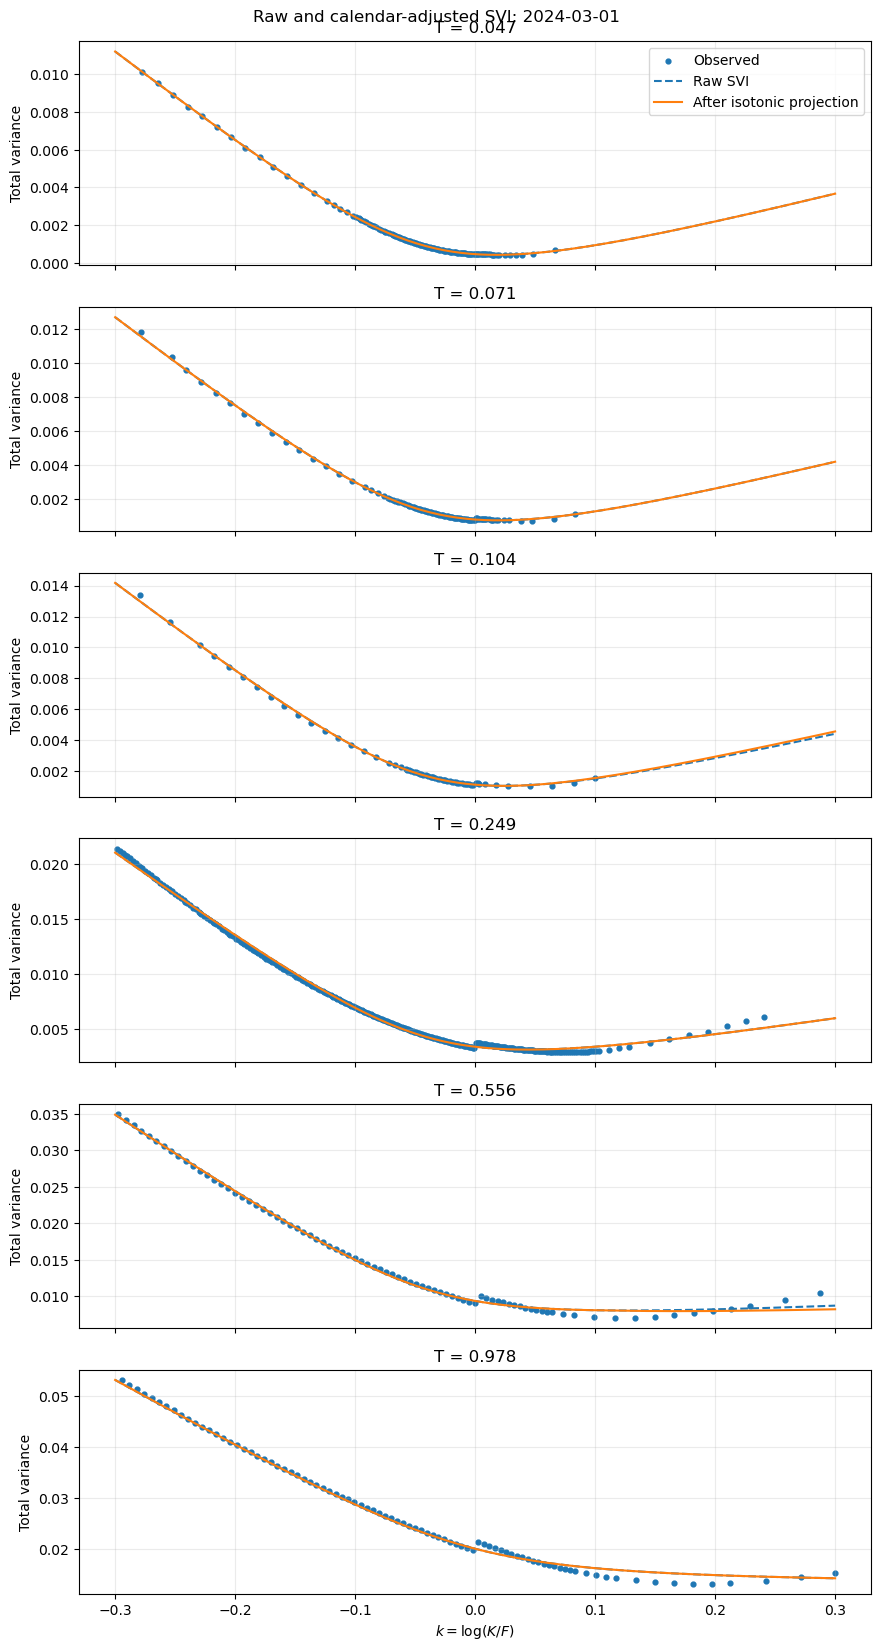

In [13]:
def build_isotonic_svi_surface(day_parameters):
    day_parameters = day_parameters.sort_values("T")

    maturities = day_parameters["T"].to_numpy(float)

    raw_w = np.vstack(
        [
            svi_total_variance(
                SVI_K_GRID,
                row.a,
                row.p,
                row.q,
                row.m,
                row.sigma,
            )
            for row in day_parameters.itertuples(index=False)
        ]
    )

    isotonic = IsotonicRegression(
        increasing=True,
        out_of_bounds="clip",
    )

    isotonic_w = np.column_stack(
        [
            isotonic.fit_transform(
                maturities,
                raw_w[:, column],
            )
            for column in range(len(SVI_K_GRID))
        ]
    )

    # Total variance cannot be negative.
    isotonic_w = np.maximum(isotonic_w, 0.0)

    time_nodes = np.concatenate(([0.0], maturities))
    w_nodes = np.vstack(
        [np.zeros(len(SVI_K_GRID)), isotonic_w]
    )

    time_grid = np.unique(
        np.concatenate(
            [
                np.linspace(
                    0.0,
                    maturities[-1],
                    SVI_TIME_POINTS,
                ),
                maturities,
            ]
        )
    )

    w_grid = np.empty(
        (len(time_grid), len(SVI_K_GRID))
    )
    w_T_grid = np.empty_like(w_grid)

    for column in range(len(SVI_K_GRID)):
        interpolator = PchipInterpolator(
            time_nodes,
            w_nodes[:, column],
            extrapolate=False,
        )

        w_grid[:, column] = interpolator(time_grid)
        w_T_grid[:, column] = interpolator.derivative()(time_grid)

    total_variance_interpolator = RegularGridInterpolator(
        (time_grid, SVI_K_GRID),
        w_grid,
        bounds_error=False,
        fill_value=np.nan,
    )

    raw_calendar_difference = (
        np.diff(raw_w, axis=0)
        if len(maturities) > 1
        else np.empty((0, len(SVI_K_GRID)))
    )

    return {
        "maturities": maturities,
        "time_nodes": time_nodes,
        "time_grid": time_grid,
        "k_grid": SVI_K_GRID.copy(),
        "raw_w_nodes": raw_w,
        "isotonic_w_nodes": isotonic_w,
        "w_grid": w_grid,
        "w_T_grid": w_T_grid,
        "total_variance_interpolator": total_variance_interpolator,
        "minimum_raw_calendar_increment": (
            float(np.min(raw_calendar_difference))
            if raw_calendar_difference.size
            else np.nan
        ),
        "fraction_negative_raw_w": float(
            np.mean(raw_w < 0.0)
        ),
        "calendar_projection_rmse": float(
            np.sqrt(np.mean((isotonic_w - raw_w) ** 2))
        ),
    }


def build_all_isotonic_surfaces(parameters):
    models = {}
    diagnostic_rows = []

    for date, day_parameters in tqdm(
        parameters.groupby("date", sort=True),
        total=parameters["date"].nunique(),
        desc="Building isotonic SVI surfaces",
    ):
        if len(day_parameters) < MIN_EXPIRIES_PER_DATE:
            continue

        model = build_isotonic_svi_surface(day_parameters)
        models[pd.Timestamp(date)] = model

        diagnostic_rows.append(
            {
                "date": pd.Timestamp(date),
                "number_of_expiries": len(day_parameters),
                "minimum_raw_calendar_increment": (
                    model["minimum_raw_calendar_increment"]
                ),
                "fraction_negative_raw_w": (
                    model["fraction_negative_raw_w"]
                ),
                "calendar_projection_rmse": (
                    model["calendar_projection_rmse"]
                ),
            }
        )

    return models, pd.DataFrame(diagnostic_rows)


surface_cache = SVI_PATCH_CACHE / "isotonic_svi_surfaces.pkl"
surface_diagnostic_cache = (
    SVI_PATCH_CACHE / "calendar_diagnostics.pkl"
)

if surface_cache.exists() and surface_diagnostic_cache.exists():
    print("Loading cached isotonic SVI surfaces.")
    svi_models = pd.read_pickle(surface_cache)
    calendar_diagnostics = pd.read_pickle(
        surface_diagnostic_cache
    )

else:
    svi_models, calendar_diagnostics = (
        build_all_isotonic_surfaces(svi_parameters)
    )

    pd.to_pickle(svi_models, surface_cache)
    calendar_diagnostics.to_pickle(
        surface_diagnostic_cache
    )
    print("Saved isotonic SVI surfaces.")


def surface_total_variance(model, k, T):
    k = np.asarray(k, float)
    T = np.asarray(T, float)
    k, T = np.broadcast_arrays(k, T)

    valid_time = (
        (T >= 0.0)
        & (T <= model["time_grid"][-1] + SVI_NUMERICAL_TOLERANCE)
    )

    points = np.column_stack(
        [
            np.clip(
                T.ravel(),
                model["time_grid"][0],
                model["time_grid"][-1],
            ),
            np.clip(
                k.ravel(),
                model["k_grid"][0],
                model["k_grid"][-1],
            ),
        ]
    )

    values = model["total_variance_interpolator"](
        points
    ).reshape(k.shape)

    return np.where(valid_time, values, np.nan)


def adjusted_surface_prices(data, models):
    prices = pd.Series(np.nan, index=data.index, dtype=float)

    for date, group in data.groupby("date"):
        model = models.get(pd.Timestamp(date))

        if model is None:
            continue

        fitted_w = surface_total_variance(
            model,
            group["log_moneyness"].to_numpy(float),
            group["T"].to_numpy(float),
        )

        fitted_iv = np.where(
            fitted_w > 0.0,
            np.sqrt(
                fitted_w
                / group["T"].to_numpy(float)
            ),
            np.nan,
        )

        prices.loc[group.index] = bs_price(
            group["cp_flag"].to_numpy(),
            group["forward_price"].to_numpy(float),
            group["strike"].to_numpy(float),
            group["T"].to_numpy(float),
            group["discount"].to_numpy(float),
            fitted_iv,
        )

    return prices


svi_calibration_results = svi_calibration_quotes.copy()
svi_calibration_results["calendar_adjusted_price"] = (
    adjusted_surface_prices(
        svi_calibration_results,
        svi_models,
    )
)

svi_calibration_results["calendar_adjusted_error"] = (
    svi_calibration_results["calendar_adjusted_price"]
    - svi_calibration_results["mid"]
)

surface_price_available = (
    svi_calibration_results["calendar_adjusted_price"].notna()
)

svi_calibration_results["inside_bid_ask"] = np.where(
    surface_price_available,
    svi_calibration_results["calendar_adjusted_price"].between(
        svi_calibration_results["best_bid"],
        svi_calibration_results["best_offer"],
    ),
    np.nan,
)

surface_fit_by_date = (
    svi_calibration_results
    .groupby("date")
    .agg(
        number_of_quotes=("optionid", "size"),
        number_priced=("calendar_adjusted_price", "count"),
        price_rmse=(
            "calendar_adjusted_error",
            lambda x: np.sqrt(np.nanmean(x**2)),
        ),
        price_mae=(
            "calendar_adjusted_error",
            lambda x: np.nanmean(np.abs(x)),
        ),
        inside_bid_ask=("inside_bid_ask", "mean"),
    )
    .reset_index()
)

display(calendar_diagnostics)
display(surface_fit_by_date)


# One compact visual check.
plot_date = sorted(svi_models)[0]
plot_model = svi_models[plot_date]
plot_parameters = svi_parameters.loc[
    svi_parameters["date"].eq(plot_date)
].sort_values("T")

selected_rows = np.linspace(
    0,
    len(plot_parameters) - 1,
    min(6, len(plot_parameters)),
).round().astype(int)

figure, axes = plt.subplots(
    len(selected_rows),
    1,
    figsize=(9, 2.8 * len(selected_rows)),
    sharex=True,
)

axes = np.atleast_1d(axes)

for axis, row_number in zip(axes, selected_rows):
    row = plot_parameters.iloc[row_number]
    maturity = float(row["T"])

    observed = svi_calibration_quotes.loc[
        svi_calibration_quotes["date"].eq(plot_date)
        & np.isclose(
            svi_calibration_quotes["T"],
            maturity,
        )
    ]

    raw_curve = svi_total_variance(
        SVI_K_GRID,
        row["a"],
        row["p"],
        row["q"],
        row["m"],
        row["sigma"],
    )

    adjusted_curve = surface_total_variance(
        plot_model,
        SVI_K_GRID,
        maturity,
    )

    axis.scatter(
        observed["log_moneyness"],
        observed["market_total_variance"],
        s=12,
        label="Observed",
    )
    axis.plot(
        SVI_K_GRID,
        raw_curve,
        linestyle="--",
        label="Raw SVI",
    )
    axis.plot(
        SVI_K_GRID,
        adjusted_curve,
        label="After isotonic projection",
    )
    axis.set_ylabel("Total variance")
    axis.set_title(f"T = {maturity:.3f}")
    axis.grid(alpha=0.25)

axes[-1].set_xlabel(r"$k=\log(K/F)$")
axes[0].legend()
figure.suptitle(f"Raw and calendar-adjusted SVI: {plot_date.date()}")
figure.tight_layout()
plt.show()

## 14. Dupire local volatility on the projected grid

For total implied variance $w(k,T)$, define

$$
g(k,T)
=
\left(1-\frac{k w_k}{2w}\right)^2
-
\frac{w_k^2}{4}\left(\frac1w+\frac14\right)
+
\frac12w_{kk}.
$$

The Dupire local variance is

$$
\sigma_{\mathrm{loc}}^2(k,T)
=
\frac{w_T(k,T)}{g(k,T)}.
$$

The PCHIP derivative supplies $w_T$. Central finite differences on the common $k$-grid supply $w_k$ and $w_{kk}$, because the isotonic projection means the final surface is no longer exactly one raw-SVI formula between maturities.

The calendar projection guarantees non-decreasing node values in $T$. It does not guarantee $g>0$. Invalid local-volatility grid points remain `NaN`; no volatility floor, cap or model-specific fit gate is applied. Outside the calibrated $k$-range, the PDE uses the nearest boundary local volatility.

Computing Dupire local volatility: 100%|██████████| 20/20 [00:00<00:00, 366.98it/s]


,date,minimum_w_T,fraction_negative_w_T,minimum_g,fraction_nonpositive_g,fraction_invalid_local_volatility
0,2024-03-01,0.0,0.0,0.017490,0.000000,0.000000
1,2024-03-04,0.0,0.0,-0.010925,0.002224,0.002224
2,2024-03-05,0.0,0.0,-0.030752,0.000087,0.000087
3,2024-03-06,0.0,0.0,0.056450,0.000000,0.000000
4,2024-03-07,0.0,0.0,0.045516,0.000000,0.000000
5,2024-03-08,0.0,0.0,0.053281,0.000000,0.000000
6,2024-03-11,0.0,0.0,-0.344876,0.000578,0.000578
7,2024-03-12,0.0,0.0,0.028976,0.000000,0.000000
8,2024-03-13,0.0,0.0,-1.236864,0.009594,0.009594
9,2024-03-14,0.0,0.0,0.020087,0.000000,0.000000


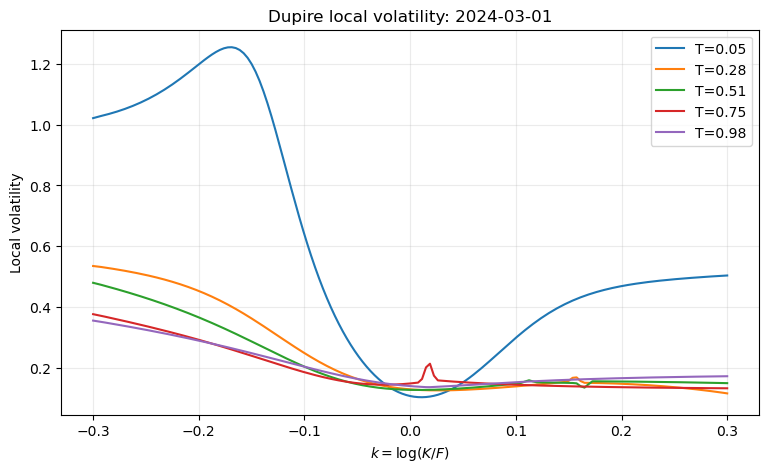

In [14]:
def attach_dupire_local_volatility(model):
    time_grid = model["time_grid"]
    k_grid = model["k_grid"]
    w = model["w_grid"]
    w_T = model["w_T_grid"].copy()

    # Monotone PCHIP should give w_T >= 0; remove only round-off negatives.
    tiny_negative = (
        (w_T < 0.0)
        & (w_T >= -SVI_NUMERICAL_TOLERANCE)
    )
    w_T[tiny_negative] = 0.0

    w_k = np.gradient(
        w,
        k_grid,
        axis=1,
        edge_order=2,
    )
    w_kk = np.gradient(
        w_k,
        k_grid,
        axis=1,
        edge_order=2,
    )

    g = np.full_like(w, np.nan)

    positive_time = time_grid > 0.0
    g[positive_time] = dupire_denominator(
        k_grid[None, :],
        w[positive_time],
        w_k[positive_time],
        w_kk[positive_time],
    )

    local_variance = np.full_like(w, np.nan)

    valid = (
        positive_time[:, None]
        & (w > 0.0)
        & (w_T >= 0.0)
        & (g > 0.0)
    )

    local_variance[valid] = w_T[valid] / g[valid]
    local_volatility = np.sqrt(local_variance)

    # Define the time-zero row by the nearest positive-time row.
    first_positive_row = np.flatnonzero(positive_time)[0]
    local_volatility[0] = local_volatility[first_positive_row]

    model = model.copy()
    model.update(
        {
            "w_k_grid": w_k,
            "w_kk_grid": w_kk,
            "g_grid": g,
            "local_volatility_grid": local_volatility,
            "local_volatility_interpolator": (
                RegularGridInterpolator(
                    (time_grid, k_grid),
                    local_volatility,
                    bounds_error=False,
                    fill_value=np.nan,
                )
            ),
        }
    )

    diagnostic = {
        "minimum_w_T": float(
            np.nanmin(w_T[positive_time])
        ),
        "fraction_negative_w_T": float(
            np.mean(
                w_T[positive_time]
                < -SVI_NUMERICAL_TOLERANCE
            )
        ),
        "minimum_g": float(
            np.nanmin(g[positive_time])
        ),
        "fraction_nonpositive_g": float(
            np.mean(g[positive_time] <= 0.0)
        ),
        "fraction_invalid_local_volatility": float(
            np.mean(
                ~np.isfinite(
                    local_volatility[positive_time]
                )
            )
        ),
    }

    return model, diagnostic


dupire_rows = []
updated_models = {}

for date, model in tqdm(
    svi_models.items(),
    total=len(svi_models),
    desc="Computing Dupire local volatility",
):
    updated_model, diagnostic = (
        attach_dupire_local_volatility(model)
    )
    updated_models[date] = updated_model
    dupire_rows.append(
        {
            "date": pd.Timestamp(date),
            **diagnostic,
        }
    )

svi_models = updated_models
dupire_diagnostics = pd.DataFrame(dupire_rows)

pd.to_pickle(
    svi_models,
    SVI_PATCH_CACHE / "svi_dupire_models.pkl",
)
dupire_diagnostics.to_pickle(
    SVI_PATCH_CACHE / "dupire_diagnostics.pkl",
)

display(dupire_diagnostics)


def local_volatility_from_model(model, k, T):
    k = np.asarray(k, float)
    T = np.asarray(T, float)
    k, T = np.broadcast_arrays(k, T)

    valid_time = (
        (T >= 0.0)
        & (T <= model["time_grid"][-1] + SVI_NUMERICAL_TOLERANCE)
    )

    points = np.column_stack(
        [
            np.clip(
                T.ravel(),
                model["time_grid"][0],
                model["time_grid"][-1],
            ),
            np.clip(
                k.ravel(),
                model["k_grid"][0],
                model["k_grid"][-1],
            ),
        ]
    )

    values = model[
        "local_volatility_interpolator"
    ](points).reshape(k.shape)

    return np.where(valid_time, values, np.nan)


# Plot one local-volatility surface cross-section.
plot_model = svi_models[plot_date]
plot_maturities = np.linspace(
    plot_model["maturities"][0],
    plot_model["maturities"][-1],
    5,
)

plt.figure(figsize=(9, 5))

for maturity in plot_maturities:
    plt.plot(
        SVI_K_GRID,
        local_volatility_from_model(
            plot_model,
            SVI_K_GRID,
            maturity,
        ),
        label=f"T={maturity:.2f}",
    )

plt.xlabel(r"$k=\log(K/F)$")
plt.ylabel("Local volatility")
plt.title(f"Dupire local volatility: {plot_date.date()}")
plt.grid(alpha=0.25)
plt.legend()
plt.show()

## 15. Backward local-volatility PDE

The frozen date-$t_0$ model is

$$
dS_t
=
b(t)S_t\,dt
+
\sigma_{\mathrm{loc}}(t,S_t)S_t\,dW_t,
$$

where $b(t)=\partial_t\log F(t)$. A European option solves

$$
V_t
+
\frac12\sigma_{\mathrm{loc}}^2(t,S)S^2V_{SS}
+
b(t)SV_S
-r(t)V
=0.
$$

The numerical coordinate is $x=\log(S/S_{\mathrm{current}})$. Crank–Nicolson advances backward from the payoff, with two Rannacher start-up steps to damp grid oscillations caused by the payoff kink.

At solver time $u$, the local volatility is evaluated at absolute model time

$$
t_{\mathrm{model}}=t_{\mathrm{offset}}+u.
$$

The offset is zero for same-day pricing and equals the elapsed year fraction for frozen next-day pricing. The day-$t_0$ forward and discount term structures remain frozen.

In [15]:
def option_boundaries(
    strikes,
    cp_flags,
    S_min,
    S_max,
    absolute_time,
    absolute_expiry,
    curve,
):
    rate_discount = discount_between(
        curve,
        absolute_time,
        absolute_expiry,
    )
    dividend_discount = dividend_discount_between(
        curve,
        absolute_time,
        absolute_expiry,
    )

    lower = np.zeros(len(strikes))
    upper = np.zeros(len(strikes))

    calls = cp_flags == "C"
    puts = cp_flags == "P"

    upper[calls] = np.maximum(
        S_max * dividend_discount
        - strikes[calls] * rate_discount,
        0.0,
    )

    lower[puts] = np.maximum(
        strikes[puts] * rate_discount
        - S_min * dividend_discount,
        0.0,
    )

    return lower, upper


def make_svi_local_volatility_function(
    model,
    curve,
    model_time_offset,
):
    def function(time_from_valuation, state_spot):
        model_time = (
            model_time_offset + time_from_valuation
        )

        forward = forward_from_curve(
            curve,
            model_time,
        )

        k = np.log(
            np.asarray(state_spot, float) / forward
        )

        return local_volatility_from_model(
            model,
            k,
            model_time,
        )

    return function


def one_backward_time_step(
    value_right,
    time_right,
    time_left,
    model_time_offset,
    absolute_expiry,
    x_grid,
    spot_grid,
    strikes,
    cp_flags,
    curve,
    local_volatility_function,
    implicit_weight,
):
    dt = time_right - time_left
    time_middle = 0.5 * (time_right + time_left)
    absolute_time_middle = (
        model_time_offset + time_middle
    )

    local_volatility = np.asarray(
        local_volatility_function(
            time_middle,
            spot_grid,
        ),
        float,
    )

    if not np.all(np.isfinite(local_volatility)):
        raise ValueError(
            "Invalid local volatility on the PDE grid."
        )

    rate = float(
        instantaneous_rate(
            curve,
            absolute_time_middle,
        )
    )
    carry = float(
        instantaneous_carry(
            curve,
            absolute_time_middle,
        )
    )

    dx = x_grid[1] - x_grid[0]

    diffusion = 0.5 * local_volatility**2
    drift = carry - 0.5 * local_volatility**2

    lower_operator = (
        diffusion / dx**2 - drift / (2.0 * dx)
    )
    diagonal_operator = (
        -2.0 * diffusion / dx**2 - rate
    )
    upper_operator = (
        diffusion / dx**2 + drift / (2.0 * dx)
    )

    inside = slice(1, len(x_grid) - 1)

    lower_left = (
        -implicit_weight * dt * lower_operator[inside]
    )
    diagonal_left = (
        1.0
        - implicit_weight * dt * diagonal_operator[inside]
    )
    upper_left = (
        -implicit_weight * dt * upper_operator[inside]
    )

    explicit_weight = 1.0 - implicit_weight

    right_hand_side = (
        (
            1.0
            + explicit_weight
            * dt
            * diagonal_operator[inside]
        )[:, None]
        * value_right[1:-1]
        + (
            explicit_weight
            * dt
            * lower_operator[inside]
        )[:, None]
        * value_right[:-2]
        + (
            explicit_weight
            * dt
            * upper_operator[inside]
        )[:, None]
        * value_right[2:]
    )

    absolute_time_left = (
        model_time_offset + time_left
    )

    lower_boundary, upper_boundary = option_boundaries(
        strikes,
        cp_flags,
        spot_grid[0],
        spot_grid[-1],
        absolute_time_left,
        absolute_expiry,
        curve,
    )

    right_hand_side[0] -= (
        lower_left[0] * lower_boundary
    )
    right_hand_side[-1] -= (
        upper_left[-1] * upper_boundary
    )

    interior_points = len(x_grid) - 2
    banded_matrix = np.zeros((3, interior_points))

    banded_matrix[0, 1:] = upper_left[:-1]
    banded_matrix[1] = diagonal_left
    banded_matrix[2, :-1] = lower_left[1:]

    value_left = value_right.copy()
    value_left[0] = lower_boundary
    value_left[-1] = upper_boundary
    value_left[1:-1] = solve_banded(
        (1, 1),
        banded_matrix,
        right_hand_side,
    )

    return value_left


def solve_local_volatility_pde_group(
    spot,
    model,
    curve,
    model_time_offset,
    absolute_expiry,
    strikes,
    cp_flags,
    local_volatility_function=None,
    space_points=PDE_SPACE_POINTS,
    time_steps_per_year=PDE_TIME_STEPS_PER_YEAR,
    log_spot_width=PDE_LOG_SPOT_WIDTH,
    rannacher_full_steps=RANNACHER_FULL_STEPS,
):
    strikes = np.asarray(strikes, float)
    cp_flags = np.asarray(cp_flags)

    remaining_maturity = (
        absolute_expiry - model_time_offset
    )

    if remaining_maturity <= 0:
        price = np.where(
            cp_flags == "C",
            np.maximum(spot - strikes, 0.0),
            np.maximum(strikes - spot, 0.0),
        )
        delta = np.where(
            cp_flags == "C",
            (spot > strikes).astype(float),
            -(spot < strikes).astype(float),
        )
        return price, delta

    if local_volatility_function is None:
        local_volatility_function = (
            make_svi_local_volatility_function(
                model,
                curve,
                model_time_offset,
            )
        )

    if space_points % 2 == 0:
        space_points += 1

    time_steps = max(
        40,
        int(
            np.ceil(
                time_steps_per_year
                * remaining_maturity
            )
        ),
    )
    time_steps = max(
        time_steps,
        rannacher_full_steps + 1,
    )

    x_grid = np.linspace(
        -log_spot_width,
        log_spot_width,
        space_points,
    )
    spot_grid = spot * np.exp(x_grid)
    dx = x_grid[1] - x_grid[0]

    value = np.where(
        cp_flags[None, :] == "C",
        np.maximum(
            spot_grid[:, None] - strikes[None, :],
            0.0,
        ),
        np.maximum(
            strikes[None, :] - spot_grid[:, None],
            0.0,
        ),
    )

    full_dt = remaining_maturity / time_steps
    time_right = remaining_maturity

    for step_number in range(time_steps):
        if step_number < rannacher_full_steps:
            for _ in range(2):
                time_left = time_right - 0.5 * full_dt

                value = one_backward_time_step(
                    value,
                    time_right,
                    time_left,
                    model_time_offset,
                    absolute_expiry,
                    x_grid,
                    spot_grid,
                    strikes,
                    cp_flags,
                    curve,
                    local_volatility_function,
                    implicit_weight=1.0,
                )

                time_right = time_left

        else:
            time_left = time_right - full_dt

            value = one_backward_time_step(
                value,
                time_right,
                time_left,
                model_time_offset,
                absolute_expiry,
                x_grid,
                spot_grid,
                strikes,
                cp_flags,
                curve,
                local_volatility_function,
                implicit_weight=0.5,
            )

            time_right = time_left

    centre = space_points // 2
    price = value[centre].copy()

    value_x = (
        value[centre + 1]
        - value[centre - 1]
    ) / (2.0 * dx)

    delta = value_x / spot

    return price, delta


def make_flat_market_curve(
    spot,
    rate,
    dividend_yield,
    maximum_time,
):
    times = np.array([0.0, maximum_time])
    carry = rate - dividend_yield

    return {
        "times": times,
        "log_forwards": np.log(spot) + carry * times,
        "log_discounts": -rate * times,
        "spot": float(spot),
    }


def constant_local_volatility_function(sigma):
    def function(time_from_valuation, state_spot):
        return np.full_like(
            np.asarray(state_spot, float),
            sigma,
            dtype=float,
        )

    return function


validation_spot = 100.0
validation_rate = 0.03
validation_dividend = 0.01
validation_sigma = 0.20
validation_maturity = 0.50
validation_strikes = np.array([80.0, 100.0, 120.0])
validation_flags = np.array(["C", "C", "C"])

validation_curve = make_flat_market_curve(
    validation_spot,
    validation_rate,
    validation_dividend,
    validation_maturity,
)

pde_price, pde_delta = solve_local_volatility_pde_group(
    validation_spot,
    model=None,
    curve=validation_curve,
    model_time_offset=0.0,
    absolute_expiry=validation_maturity,
    strikes=validation_strikes,
    cp_flags=validation_flags,
    local_volatility_function=(
        constant_local_volatility_function(
            validation_sigma
        )
    ),
)

validation_forward = forward_from_curve(
    validation_curve,
    validation_maturity,
)
validation_discount = discount_from_curve(
    validation_curve,
    validation_maturity,
)

bs_validation_price = bs_price(
    validation_flags,
    validation_forward,
    validation_strikes,
    validation_maturity,
    validation_discount,
    validation_sigma,
)

bs_validation_delta = bs_delta(
    validation_flags,
    validation_spot,
    validation_forward,
    validation_strikes,
    validation_maturity,
    validation_discount,
    validation_sigma,
)

constant_volatility_validation = pd.DataFrame(
    {
        "strike": validation_strikes,
        "pde_price": pde_price,
        "bs_price": bs_validation_price,
        "price_error": (
            pde_price - bs_validation_price
        ),
        "pde_delta": pde_delta,
        "bs_delta": bs_validation_delta,
        "delta_error": (
            pde_delta - bs_validation_delta
        ),
    }
)

display(constant_volatility_validation)

,strike,pde_price,bs_price,price_error,pde_delta,bs_delta,delta_error
0,80.0,20.951414,20.951138,0.000276,0.952399,0.952445,-0.000045
1,100.0,6.088581,6.090127,-0.001546,0.553477,0.553457,0.000020
2,120.0,0.827373,0.826946,0.000427,0.124998,0.124902,0.000096


## 16. Same-day surface fit, PDE recovery and coverage

Three quantities are kept separate:

$$
C_{\mathrm{surface}}-C_{\mathrm{market}}
$$

measures the calendar-adjusted SVI fit,

$$
C_{\mathrm{LV,PDE}}-C_{\mathrm{surface}}
$$

measures the Dupire/PDE recovery error, and

$$
C_{\mathrm{LV,PDE}}-C_{\mathrm{market}}
$$

is their sum.

Every clean quote is retained in `lv_same_day_results`. Failed prices remain `NaN` with a status label. No date is accepted or rejected according to these errors.

In [16]:
def price_dataframe_by_groups(
    data,
    models,
    curves,
    model_date_column,
    current_date_column,
    spot_column,
    absolute_expiry_column,
    strike_column,
    cp_flag_column,
    progress_description,
):
    output = pd.DataFrame(
        index=data.index,
        columns=[
            "model_price",
            "model_delta",
            "model_status",
        ],
    )

    output["model_price"] = np.nan
    output["model_delta"] = np.nan
    output["model_status"] = "not_attempted"

    group_columns = []

    for column in [
        model_date_column,
        current_date_column,
        "exdate",
        "am_settlement",
    ]:
        if column not in group_columns:
            group_columns.append(column)

    groups = data.groupby(
        group_columns,
        dropna=False,
        sort=True,
    )

    for _, group in tqdm(
        groups,
        total=len(groups),
        desc=progress_description,
    ):
        model_date = pd.Timestamp(
            group[model_date_column].iloc[0]
        )
        current_date = pd.Timestamp(
            group[current_date_column].iloc[0]
        )

        model = models.get(model_date)
        curve = curves.get(model_date)

        if model is None:
            output.loc[
                group.index,
                "model_status",
            ] = "missing_surface"
            continue

        if curve is None:
            output.loc[
                group.index,
                "model_status",
            ] = "missing_market_curve"
            continue

        model_time_offset = (
            current_date - model_date
        ).days / 365.0

        absolute_expiry = float(
            group[absolute_expiry_column].iloc[0]
        )

        if (
            absolute_expiry
            > model["time_grid"][-1]
            + SVI_NUMERICAL_TOLERANCE
        ):
            output.loc[
                group.index,
                "model_status",
            ] = "expiry_outside_surface"
            continue

        try:
            model_price, model_delta = (
                solve_local_volatility_pde_group(
                    spot=float(group[spot_column].iloc[0]),
                    model=model,
                    curve=curve,
                    model_time_offset=model_time_offset,
                    absolute_expiry=absolute_expiry,
                    strikes=group[
                        strike_column
                    ].to_numpy(float),
                    cp_flags=group[
                        cp_flag_column
                    ].to_numpy(),
                )
            )

        except (
            ValueError,
            np.linalg.LinAlgError,
            FloatingPointError,
        ):
            output.loc[
                group.index,
                "model_status",
            ] = "pde_failure"
            continue

        output.loc[group.index, "model_price"] = model_price
        output.loc[group.index, "model_delta"] = model_delta
        output.loc[group.index, "model_status"] = "ok"

    return output


same_day_cache = (
    SVI_PATCH_CACHE / "same_day_pde_results.pkl"
)

if same_day_cache.exists():
    print("Loading cached same-day PDE results.")
    same_day_pde = pd.read_pickle(same_day_cache)

else:
    same_day_pde = price_dataframe_by_groups(
        quotes_all,
        svi_models,
        market_curves,
        model_date_column="date",
        current_date_column="date",
        spot_column="spot",
        absolute_expiry_column="T",
        strike_column="strike",
        cp_flag_column="cp_flag",
        progress_description="Same-day SVI-LV PDE pricing",
    )

    same_day_pde.to_pickle(same_day_cache)
    print("Saved same-day PDE results.")


lv_same_day_results = quotes_all.copy()

lv_same_day_results["surface_price"] = (
    adjusted_surface_prices(
        lv_same_day_results,
        svi_models,
    )
)

lv_same_day_results["lv_price"] = (
    same_day_pde["model_price"]
)
lv_same_day_results["lv_delta"] = (
    same_day_pde["model_delta"]
)
lv_same_day_results["lv_status"] = (
    same_day_pde["model_status"]
)

lv_same_day_results["surface_market_error"] = (
    lv_same_day_results["surface_price"]
    - lv_same_day_results["mid"]
)
lv_same_day_results["pde_surface_error"] = (
    lv_same_day_results["lv_price"]
    - lv_same_day_results["surface_price"]
)
lv_same_day_results["lv_market_error"] = (
    lv_same_day_results["lv_price"]
    - lv_same_day_results["mid"]
)

lv_same_day_results["surface_inside_bid_ask"] = np.where(
    lv_same_day_results["surface_price"].notna(),
    lv_same_day_results["surface_price"].between(
        lv_same_day_results["best_bid"],
        lv_same_day_results["best_offer"],
    ),
    np.nan,
)

lv_same_day_results["lv_inside_bid_ask"] = np.where(
    lv_same_day_results["lv_price"].notna(),
    lv_same_day_results["lv_price"].between(
        lv_same_day_results["best_bid"],
        lv_same_day_results["best_offer"],
    ),
    np.nan,
)

same_day_success = lv_same_day_results.loc[
    lv_same_day_results["lv_status"].eq("ok")
].copy()

same_day_coverage = pd.Series(
    {
        "candidate_quotes": len(lv_same_day_results),
        "surface_prices_available": (
            lv_same_day_results["surface_price"].notna().sum()
        ),
        "pde_prices_available": len(same_day_success),
        "pde_quote_coverage": (
            len(same_day_success)
            / len(lv_same_day_results)
        ),
        "candidate_dates": (
            lv_same_day_results["date"].nunique()
        ),
        "dates_with_any_pde_price": (
            same_day_success["date"].nunique()
        ),
    }
)

same_day_metrics = pd.Series(
    {
        "surface_market_rmse": np.sqrt(
            np.nanmean(
                lv_same_day_results[
                    "surface_market_error"
                ] ** 2
            )
        ),
        "surface_market_mae": np.nanmean(
            np.abs(
                lv_same_day_results[
                    "surface_market_error"
                ]
            )
        ),
        "surface_inside_bid_ask": np.nanmean(
            lv_same_day_results[
                "surface_inside_bid_ask"
            ]
        ),
        "pde_surface_rmse": np.sqrt(
            np.mean(
                same_day_success[
                    "pde_surface_error"
                ] ** 2
            )
        ),
        "pde_surface_mae": np.mean(
            np.abs(
                same_day_success[
                    "pde_surface_error"
                ]
            )
        ),
        "lv_market_rmse": np.sqrt(
            np.mean(
                same_day_success[
                    "lv_market_error"
                ] ** 2
            )
        ),
        "lv_market_mae": np.mean(
            np.abs(
                same_day_success[
                    "lv_market_error"
                ]
            )
        ),
        "lv_inside_bid_ask": np.mean(
            same_day_success[
                "lv_inside_bid_ask"
            ]
        ),
    }
)

same_day_failure_counts = (
    lv_same_day_results["lv_status"]
    .value_counts(dropna=False)
    .rename("number_of_quotes")
)

display(same_day_coverage)
display(same_day_metrics)
display(same_day_failure_counts)

Loading cached same-day PDE results.


candidate_quotes            243997.000000
surface_prices_available    243997.000000
pde_prices_available        136054.000000
pde_quote_coverage               0.557605
candidate_dates                 20.000000
dates_with_any_pde_price        13.000000
dtype: float64

surface_market_rmse       5.846639
surface_market_mae        4.115018
surface_inside_bid_ask    0.151260
pde_surface_rmse          1.753526
pde_surface_mae           1.371209
lv_market_rmse            6.683229
lv_market_mae             4.775290
lv_inside_bid_ask         0.128398
dtype: float64

lv_status
ok             136054
pde_failure    107943
Name: number_of_quotes, dtype: int64

## 17. Frozen next-day pricing and one-day delta hedging

For an option model calibrated on date $t$, the next trading date is evaluated using:

- the realised next-day spot;
- the original date-$t$ SVI/LV surface;
- the original date-$t$ forward and discount term structures;
- absolute model time shifted by the elapsed year fraction.

The one-day hedge error is kept identical to the BS benchmark:

$$
\varepsilon_{t,t+1}
=
(C_{t+1}-C_t)
-
\Delta_t(S_{t+1}-S_t).
$$

`lv_pair_results` retains every common candidate pair. The metrics use rows on which LV returned the required values, while `next_day_coverage` and `next_day_failure_counts` show the missing share. Use `pair_id` to form an identical model-comparison sample later.

In [17]:
next_day_cache = (
    SVI_PATCH_CACHE / "next_day_pde_results.pkl"
)

if next_day_cache.exists():
    print("Loading cached frozen next-day PDE results.")
    next_day_pde = pd.read_pickle(next_day_cache)

else:
    next_day_pde = price_dataframe_by_groups(
        evaluation_pairs,
        svi_models,
        market_curves,
        model_date_column="date",
        current_date_column="date_next",
        spot_column="spot_next",
        absolute_expiry_column="T",
        strike_column="strike_next",
        cp_flag_column="cp_flag_next",
        progress_description="Frozen next-day SVI-LV PDE pricing",
    )

    next_day_pde.to_pickle(next_day_cache)
    print("Saved frozen next-day PDE results.")


pair_base = evaluation_pairs.copy()
pair_base["next_day_lv_price"] = (
    next_day_pde["model_price"]
)
pair_base["next_day_lv_status"] = (
    next_day_pde["model_status"]
)

today_lv_columns = lv_same_day_results[
    [
        "date",
        "optionid",
        "lv_price",
        "lv_delta",
        "lv_status",
    ]
].rename(
    columns={
        "lv_price": "same_day_lv_price",
        "lv_delta": "same_day_lv_delta",
        "lv_status": "same_day_lv_status",
    }
)

lv_pair_results = pair_base.merge(
    today_lv_columns,
    on=["date", "optionid"],
    how="left",
    validate="one_to_one",
)

lv_pair_results["next_day_price_error"] = (
    lv_pair_results["next_day_lv_price"]
    - lv_pair_results["mid_next"]
)

lv_pair_results["hedging_error"] = (
    lv_pair_results["option_change"]
    - lv_pair_results["same_day_lv_delta"]
    * (
        lv_pair_results["spot_next"]
        - lv_pair_results["spot"]
    )
)

lv_pair_results["next_day_success"] = (
    lv_pair_results["next_day_lv_status"].eq("ok")
)
lv_pair_results["hedge_success"] = (
    lv_pair_results["next_day_success"]
    & lv_pair_results["same_day_lv_delta"].notna()
)

price_success = lv_pair_results.loc[
    lv_pair_results["next_day_success"]
].copy()

hedge_success = lv_pair_results.loc[
    lv_pair_results["hedge_success"]
].copy()

next_day_coverage = pd.Series(
    {
        "candidate_pairs": len(lv_pair_results),
        "next_day_prices_available": len(price_success),
        "next_day_pair_coverage": (
            len(price_success) / len(lv_pair_results)
        ),
        "hedges_available": len(hedge_success),
        "hedge_pair_coverage": (
            len(hedge_success) / len(lv_pair_results)
        ),
        "candidate_model_dates": (
            lv_pair_results["date"].nunique()
        ),
        "model_dates_with_any_next_day_price": (
            price_success["date"].nunique()
        ),
    }
)

next_day_failure_counts = (
    lv_pair_results["next_day_lv_status"]
    .value_counts(dropna=False)
    .rename("number_of_pairs")
)


def pair_summary(data):
    price_data = data.loc[data["next_day_success"]]
    hedge_data = data.loc[data["hedge_success"]]

    if price_data.empty:
        return pd.Series(dtype=float)

    inside_bid_ask = price_data[
        "next_day_lv_price"
    ].between(
        price_data["best_bid_next"],
        price_data["best_offer_next"],
    )

    result = {
        "candidate_pairs": len(data),
        "priced_pairs": len(price_data),
        "hedged_pairs": len(hedge_data),
        "next_day_price_rmse": np.sqrt(
            np.mean(price_data["next_day_price_error"] ** 2)
        ),
        "next_day_price_mae": np.mean(
            np.abs(price_data["next_day_price_error"])
        ),
        "next_day_inside_bid_ask": inside_bid_ask.mean(),
        "unhedged_mae": np.mean(
            np.abs(price_data["option_change"])
        ),
    }

    if not hedge_data.empty:
        result.update(
            {
                "hedging_rmse": np.sqrt(
                    np.mean(hedge_data["hedging_error"] ** 2)
                ),
                "hedging_mae": np.mean(
                    np.abs(hedge_data["hedging_error"])
                ),
                "hedging_bias": np.mean(
                    hedge_data["hedging_error"]
                ),
                "hedging_improvement": (
                    1.0
                    - np.mean(
                        np.abs(hedge_data["hedging_error"])
                    )
                    / np.mean(
                        np.abs(hedge_data["option_change"])
                    )
                ),
            }
        )

    return pd.Series(result)


lv_summary = pd.DataFrame(
    {
        "all_candidate_pairs": pair_summary(
            lv_pair_results
        ),
        "otm_candidate_pairs": pair_summary(
            lv_pair_results.loc[
                lv_pair_results["is_otm"]
            ]
        ),
    }
).T

display(next_day_coverage)
display(next_day_failure_counts)
display(lv_summary)

Loading cached frozen next-day PDE results.


candidate_pairs                        224566.000000
next_day_prices_available              130819.000000
next_day_pair_coverage                      0.582541
hedges_available                       130819.000000
hedge_pair_coverage                         0.582541
candidate_model_dates                      19.000000
model_dates_with_any_next_day_price        12.000000
dtype: float64

next_day_lv_status
ok             130819
pde_failure     93747
Name: number_of_pairs, dtype: int64

,candidate_pairs,priced_pairs,hedged_pairs,next_day_price_rmse,next_day_price_mae,next_day_inside_bid_ask,unhedged_mae,hedging_rmse,hedging_mae,hedging_bias,hedging_improvement
all_candidate_pairs,224566.0,130819.0,130819.0,7.826430,5.910404,0.083474,12.484854,3.610233,2.826662,0.420733,0.773593
otm_candidate_pairs,115993.0,67480.0,67480.0,4.457174,3.175420,0.039152,4.341085,3.382458,2.558128,0.496935,0.410717


## 18. Save outputs and comparison discipline

The saved result tables retain success flags and failure statuses.

For a direct comparison with BS-IVF:

1. join the two model outputs on `pair_id`;
2. define one common comparison sample before calculating either model's metrics;
3. report each model's coverage on the original candidate sample;
4. report same-day surface error separately from PDE recovery error.

The raw-SVI parameters describe the initial expiry fits. The final local-volatility surface is the isotonic maturity projection, so its price fit is given by `svi_calibration_results` and `lv_same_day_results`, not by the raw-slice diagnostics alone.

In [18]:
output_folder = Path("local_vol_svi_patch_outputs")
output_folder.mkdir(exist_ok=True)

svi_parameters.to_csv(
    output_folder / "raw_svi_parameters.csv",
    index=False,
)
svi_slice_diagnostics.to_csv(
    output_folder / "raw_svi_slice_diagnostics.csv",
    index=False,
)
svi_slice_failures.to_csv(
    output_folder / "raw_svi_slice_failures.csv",
    index=False,
)
calendar_diagnostics.to_csv(
    output_folder / "calendar_projection_diagnostics.csv",
    index=False,
)
dupire_diagnostics.to_csv(
    output_folder / "dupire_diagnostics.csv",
    index=False,
)
surface_fit_by_date.to_csv(
    output_folder / "calendar_adjusted_surface_fit_by_date.csv",
    index=False,
)
lv_same_day_results.to_csv(
    output_folder / "same_day_results.csv",
    index=False,
)
lv_pair_results.to_csv(
    output_folder / "next_day_and_hedging_results.csv",
    index=False,
)
same_day_coverage.to_csv(
    output_folder / "same_day_coverage.csv",
    header=["value"],
)
same_day_metrics.to_csv(
    output_folder / "same_day_metrics.csv",
    header=["value"],
)
next_day_coverage.to_csv(
    output_folder / "next_day_coverage.csv",
    header=["value"],
)
lv_summary.to_csv(
    output_folder / "next_day_and_hedging_metrics.csv"
)

print("Saved outputs to:", output_folder.resolve())

Saved outputs to: C:\Users\Startklar\ICL\NDEs\Codes\LV\local_vol_svi_patch_outputs


## References

1. J. Gatheral and A. Jacquier, **Arbitrage-free SVI volatility surfaces**, *Quantitative Finance* 14(1), 2014. Sections 3 and 5 provide the SVI parameterisation, density condition and slice-calibration framework.  
   https://arxiv.org/abs/1204.0646

2. Zeliade Systems, **Quasi-explicit calibration of Gatheral's SVI model**, 2009. The reduction to a two-dimensional nonlinear search is the basis of Section 12.  
   https://www.zeliade.com/whitepapers/zwp-0005.pdf

3. IceCurrent, **Local Volatility Surface for SPX Options**. The repository uses quasi-explicit SVI, calendar correction on a common grid, Dupire local volatility and Crank–Nicolson pricing. The present notebook is a smaller independent implementation.  
   https://github.com/IceCurrent/local_volatility_model

4. J. Gatheral, **The Volatility Surface: A Practitioner's Guide**, Chapter 1. Dupire local volatility in implied-variance coordinates.

5. M. Giles and R. Carter, **Convergence analysis of Crank–Nicolson and Rannacher time-marching**, *Journal of Computational Finance* 9(4), 2006.  
   https://people.maths.ox.ac.uk/gilesm/files/giles_carter.pdf

## Interpretation checklist

Before treating the benchmark results as meaningful, verify:

1. **Calibration availability:** enough dates have at least three eligible expiries.
2. **SSVI fit:** total implied variance RMSE is small relative to observed total implied variance.
3. **Calendar-spread condition:** `fraction_w_T_negative` is zero or numerically negligible.
4. **Butterfly condition:** `fraction_dupire_denominator_nonpositive` is zero.
5. **Safeguard use:** `fraction_local_volatility_safeguarded` is small and reported.
6. **PDE validation:** constant local volatility reproduces Black-Scholes price and delta.
7. **Grid convergence:** the price and delta stabilise under refinement.
8. **Same-day reconstruction:** local-volatility PDE prices approximately recover the fitted vanilla surface.
9. **Next-day comparison:** use the intersection of `pair_id` across models.
10. **Hedge interpretation:** the PDE delta holds the calibrated day-$t$ local-volatility model fixed.

The SSVI specification is intentionally restrictive: one $\rho$ and one Heston-like backbone parameter $\lambda$ are shared across all maturities on a date. This gives a transparent, static-arbitrage-controlled baseline, but a less accurate fit than a more flexible per-expiry SVI or extended SSVI surface is possible.